# HW2 · Part 2 — Single-stock risk report (parameterised)

**Author:** Shashank Mishra · **Reads:** `ohlc_hw_cleaned` (written by `01_data_cleaning.ipynb`)

One notebook, one stock, one window. Change the parameters (or let `03_run_all_stocks.py` change them through papermill) and the same report is produced for any ticker. The notebook is organised as **load → verify → compute → draw → summarise → export**.

Conventions, so the numbers can be read correctly:

* Prices for performance and risk are **adjusted close**; raw OHLC is only used for input checks.
* Returns are **daily log returns** `ln(P_t / P_{t-1})`. The first return is undefined, never zero.
* Volatility is annualised with `sqrt(252)`; the rolling window is 20 returns, so it needs 21 prices.
* Everything is kept as a **fraction** in calculations and exports; percentages appear only in labels.

In [1]:
import sqlite3
from contextlib import closing
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scrapbook as sb
from IPython.display import display
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

%matplotlib inline

## 2.1 Parameters

The cell below carries the Jupyter cell tag **`parameters`** (checked in the notebook metadata, not just the comment). Papermill replaces these values by inserting an `injected-parameters` cell right after it. `db_path` is relative to the working directory so the notebook is portable.

In [2]:
# Parameters
ticker = "AAPL"             # Stock ticker to analyze
start_date = "2024-01-01"   # Analysis start date
end_date = "2024-12-31"     # Analysis end date
db_path = "data/data.db"    # Local working copy that holds ohlc_hw_cleaned

In [3]:
# Parameters
ticker = "IBM"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "data/data.db"


## 2.3 Risk-metric functions

Defined first so each can be checked on numbers small enough to verify by hand. Every function is pure (no globals except the named constants).

In [4]:
TRADING_DAYS = 252      # annualisation factor
RISK_FREE = 0.02        # annual risk-free rate used by the course Sharpe approximation
VOL_WINDOW = 20         # rolling-volatility window, in returns
MA_WINDOW = 50          # moving-average window, in prices


def calculate_returns(prices: pd.Series) -> pd.Series:
    """Daily log returns, ln(P_t / P_{t-1}).

    `prices` must be sorted by date with finite, positive values. The first return is NaN
    (there is no previous price); it is never replaced with zero.
    """
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = VOL_WINDOW) -> pd.Series:
    """Annualised rolling volatility: sample std (ddof=1) of `window` returns x sqrt(252).

    The first `window` entries of a return series are NaN (warm-up), so the first value
    appears once `window` real returns exist, i.e. at the (window+1)-th price.
    """
    return returns.rolling(window).std() * np.sqrt(TRADING_DAYS)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Per-date drawdown from the running peak: (price - running_max) / running_max.

    The name is kept from the assignment, but the *series* can recover toward 0.
    The maximum drawdown is `.min()` of this series; `.cummin()` would give the worst
    drawdown reached so far.
    """
    running_peak = prices.cummax()
    return (prices - running_peak) / running_peak


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = RISK_FREE) -> float:
    """Annualised Sharpe approximation: (mean*252 - rf) / (std*sqrt(252)) from daily log returns.

    Returns NaN with fewer than two returns or when the standard deviation is zero/non-finite.
    """
    r = returns.dropna()
    sigma = r.std()
    if len(r) < 2 or not np.isfinite(sigma) or np.isclose(sigma, 0.0):
        return float("nan")
    return float((r.mean() * TRADING_DAYS - risk_free_rate) / (sigma * np.sqrt(TRADING_DAYS)))

In [5]:
# Hand-checkable tests (these run every time, in every generated report).
toy = pd.Series([80.0, 100.0, 70.0, 85.0])
toy_dd = calculate_max_drawdown(toy)
assert np.allclose(toy_dd, [0.0, 0.0, -0.30, -0.15]), toy_dd           # worst -30%, final -15%
assert np.isclose(toy_dd.min(), -0.30) and np.isclose(toy_dd.iloc[-1], -0.15)
assert np.isclose(calculate_returns(toy).iloc[1], np.log(100 / 80)) and np.isnan(calculate_returns(toy).iloc[0])
ramp = pd.Series(100 * np.exp(np.cumsum(np.r_[0.0, np.full(25, 0.01)])))          # 25 identical returns
assert calculate_volatility(calculate_returns(ramp)).iloc[:20].isna().all(), "warm-up must stay NaN"
assert np.isclose(calculate_volatility(calculate_returns(ramp)).iloc[20], 0.0)   # identical returns -> zero spread
assert np.isnan(calculate_sharpe_ratio(pd.Series([0.01, 0.01, 0.01]))) and np.isnan(calculate_sharpe_ratio(pd.Series([0.01])))
print("Metric functions pass their hand checks.")

Metric functions pass their hand checks.


## 2.2 Load the cleaned data

`load_prices` validates *before* it trusts anything: dates parse and are ordered, the database and table exist, the ticker is known, and there are enough prices (**20 returns need 21 prices**). Each failure raises a message that says what to fix, which is what the batch script logs for a failed ticker.

In [6]:
def load_prices(db_path: str, ticker: str, start: str, end: str) -> pd.DataFrame:
    """Cleaned OHLCV + adj_close for one ticker/date window, indexed by date."""
    first, last = pd.Timestamp(start), pd.Timestamp(end)
    if first > last:
        raise ValueError(f"start_date {start} is after end_date {end}.")
    database = Path(db_path).expanduser().resolve()
    if not database.is_file():
        raise FileNotFoundError(f"Database not found: {database}. Run 01_data_cleaning.ipynb first.")
    symbol = str(ticker).strip().upper()
    with closing(sqlite3.connect(f"{database.as_uri()}?mode=ro", uri=True)) as conn:
        tables = {row[0] for row in conn.execute("SELECT name FROM sqlite_master WHERE type='table'")}
        if "ohlc_hw_cleaned" not in tables:
            raise LookupError("Table ohlc_hw_cleaned is missing. Run 01_data_cleaning.ipynb first.")
        universe = [row[0] for row in conn.execute("SELECT DISTINCT ticker FROM ohlc_hw_cleaned ORDER BY ticker")]
        if symbol not in universe:
            raise LookupError(f"Unknown ticker {symbol!r}; {len(universe)} tickers available: {', '.join(universe)}.")
        frame = pd.read_sql_query(
            "SELECT ts, open, high, low, close, adj_close, volume FROM ohlc_hw_cleaned "
            "WHERE ticker = ? AND ts BETWEEN ? AND ? ORDER BY ts",
            conn, params=(symbol, first.strftime("%Y-%m-%d"), last.strftime("%Y-%m-%d")), parse_dates=["ts"], index_col="ts")
    needed = VOL_WINDOW + 1
    if len(frame) < needed:
        raise ValueError(f"{symbol}: {len(frame)} prices between {start} and {end}; "
                         f"{VOL_WINDOW} returns require at least {needed} prices.")
    return frame


def input_checks(frame: pd.DataFrame) -> pd.Series:
    """Boolean pass/fail for the properties the metrics rely on."""
    prices = frame[["open", "high", "low", "close", "adj_close"]]
    return pd.Series({
        "dates_sorted_unique": frame.index.is_monotonic_increasing and frame.index.is_unique,
        "prices_finite_positive": bool(np.isfinite(prices.to_numpy()).all() and (prices > 0).all().all()),
        "ohlc_bounds_valid": bool((frame["low"] <= frame[["open", "close"]].min(axis=1)).all()
                                  and (frame["high"] >= frame[["open", "close"]].max(axis=1)).all()),
        "volume_finite_nonnegative": bool(np.isfinite(frame["volume"]).all() and (frame["volume"] >= 0).all()),
    })


df = load_prices(db_path, ticker, start_date, end_date)
checks = input_checks(df)
data_quality_ok = bool(checks.all())
if not data_quality_ok:
    raise ValueError(f"{ticker}: input checks failed -> {checks[~checks].index.tolist()}")

TICKER = ticker.strip().upper()
print(f"{TICKER} from {start_date} to {end_date}: {len(df)} trading days")
print(f"Actual first / last observation: {df.index[0]:%Y-%m-%d} / {df.index[-1]:%Y-%m-%d}")
shortfall = (pd.Timestamp(end_date) - df.index[-1]).days
if shortfall > 7:
    print(f"NOTE: history ends {shortfall} calendar days before the requested end date; the report covers only the observed period.")
display(df.head(3))
display(df.tail(3))

IBM from 2024-06-01 to 2024-11-30: 126 trading days
Actual first / last observation: 2024-06-03 / 2024-11-29


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-06-03,166.54,166.78,163.53,165.28,162.57,2776100
2024-06-04,164.60,166.40,163.88,165.81,163.09,2594203
2024-06-05,166.41,167.79,165.78,167.38,164.63,3049400


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-11-26,226.73,228.98,225.51,228.83,228.83,4449543
2024-11-27,228.83,229.19,224.27,226.92,226.92,2995121
2024-11-29,227.75,230.36,227.19,227.41,227.41,2640300


## Compute the metrics

Everything the report shows is built from `adj_close`. The 50-day average is *unavailable* (not zero) until 50 prices exist, and the rolling volatility until 21.

In [7]:
df["log_return"] = calculate_returns(df["adj_close"])
df["volatility"] = calculate_volatility(df["log_return"])
df["drawdown"] = calculate_max_drawdown(df["adj_close"])
df["ma50"] = df["adj_close"].rolling(MA_WINDOW).mean()

r = df["log_return"].dropna()
n_returns = len(r)
mean_vol = df["volatility"].mean()
metrics = {
    "total_return": df["adj_close"].iloc[-1] / df["adj_close"].iloc[0] - 1,
    "annualized_return": float(np.expm1(r.sum() * TRADING_DAYS / n_returns)),
    "annualized_volatility": float(r.std() * np.sqrt(TRADING_DAYS)),
    "sharpe_ratio": calculate_sharpe_ratio(r),
    "max_drawdown": float(df["drawdown"].min()),
    "best_day": float(r.max()),
    "worst_day": float(r.min()),
    "positive_days": float((r > 0).sum() / n_returns),
    "avg_up_day": float(r[r > 0].mean()) if (r > 0).any() else float("nan"),
    "avg_down_day": float(r[r < 0].mean()) if (r < 0).any() else float("nan"),
    "avg_daily_return": float(r.mean()),
    "avg_volatility": float(mean_vol),
}
# Cross-checks: compounding the log returns reproduces the price ratio, and the worst drawdown lies on the path.
assert np.isclose(np.expm1(r.sum()), metrics["total_return"])
assert metrics["max_drawdown"] <= 0 and df["drawdown"].idxmin() in df.index
print(f"{n_returns} log returns | mean rolling volatility {mean_vol:.2%} | 50-day average available from "
      f"{df['ma50'].first_valid_index():%Y-%m-%d}" if df["ma50"].notna().any() else
      f"{n_returns} log returns | mean rolling volatility {mean_vol:.2%} | only {len(df)} prices: the 50-day average needs {MA_WINDOW}")

125 log returns | mean rolling volatility 19.93% | 50-day average available from 2024-08-13


## 2.4 Visualisation

A 2×2 grid, 16×12 inches. The colour code is the same everywhere: **green = calm / gain, red = turbulent / loss, grey = not enough history yet**. The price line is drawn as one `LineCollection` so every segment can carry its own colour in a single artist (segment *i* takes the colour of the volatility on its end date, relative to this report's mean). Because the threshold is the report's own mean, the colouring is retrospective.

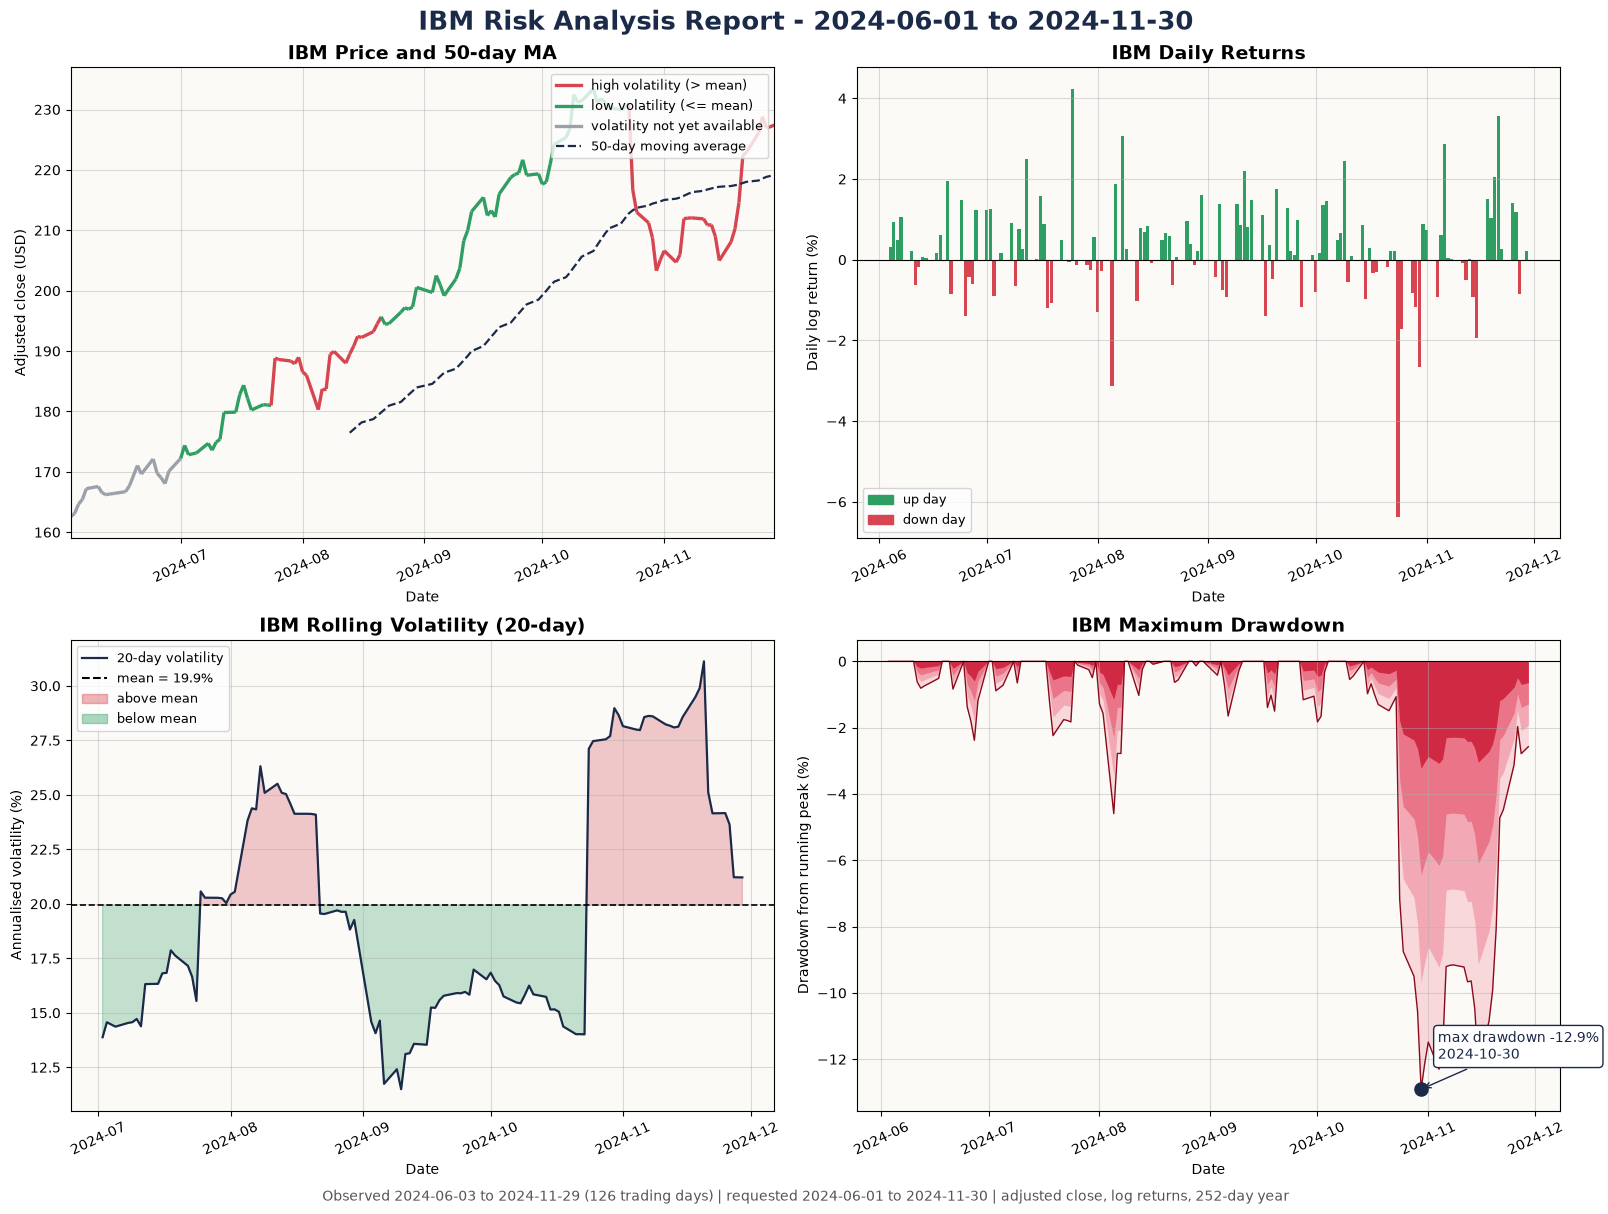

In [8]:
GREEN, RED, GREY = "#2f9e63", "#d64550", "#9aa1a9"
NAVY, GOLD, PAPER = "#1b2a49", "#d4a017", "#fbfaf7"


def segment_colors(volatility: pd.Series, threshold: float) -> np.ndarray:
    """Colour of each price segment: grey while volatility is undefined, red above the mean, green otherwise."""
    end_vol = volatility.to_numpy()[1:]
    return np.where(np.isnan(end_vol), GREY, np.where(end_vol > threshold, RED, GREEN))


fig, axes = plt.subplots(2, 2, figsize=(16, 12), layout="constrained", facecolor="white")
fig.suptitle(f"{TICKER} Risk Analysis Report - {start_date} to {end_date}", fontsize=19, fontweight="bold", color=NAVY)
dates = mdates.date2num(df.index.to_pydatetime())

# --- top left: adjusted price coloured by volatility regime, with the 50-day average -------------------------
ax = axes[0, 0]
points = np.column_stack([dates, df["adj_close"].to_numpy()])
segments = np.stack([points[:-1], points[1:]], axis=1)
ax.add_collection(LineCollection(segments, colors=segment_colors(df["volatility"], mean_vol), linewidths=2.4))
ax.plot(df.index, df["ma50"], color=NAVY, lw=1.6, ls="--")
pad = 0.05 * (df["adj_close"].max() - df["adj_close"].min() or 1.0)
ax.set(xlim=(dates[0], dates[-1]), ylim=(df["adj_close"].min() - pad, df["adj_close"].max() + pad),
       title=f"{TICKER} Price and 50-day MA", ylabel="Adjusted close (USD)")
ax.xaxis_date()
ax.legend(handles=[Line2D([], [], color=RED, lw=2.4, label="high volatility (> mean)"),
                   Line2D([], [], color=GREEN, lw=2.4, label="low volatility (<= mean)"),
                   Line2D([], [], color=GREY, lw=2.4, label="volatility not yet available"),
                   Line2D([], [], color=NAVY, lw=1.6, ls="--", label="50-day moving average")], loc="best", fontsize=9)
if df["ma50"].isna().all():
    ax.text(0.5, 0.06, f"50-day MA needs {MA_WINDOW} prices; only {len(df)} available", transform=ax.transAxes,
            ha="center", color=NAVY, fontsize=10, bbox=dict(boxstyle="round", fc="white", ec=GREY))

# --- top right: daily log returns as signed bars --------------------------------------------------------------
ax = axes[0, 1]
ax.bar(df.index, df["log_return"] * 100, width=0.9, color=np.where(df["log_return"].fillna(0) >= 0, GREEN, RED))
ax.axhline(0, color="black", lw=0.8)
ax.set(title=f"{TICKER} Daily Returns", ylabel="Daily log return (%)")
ax.legend(handles=[Patch(color=GREEN, label="up day"), Patch(color=RED, label="down day")], loc="best", fontsize=9)

# --- bottom left: rolling volatility around its mean ------------------------------------------------------------
ax = axes[1, 0]
vol_pct = df["volatility"] * 100
ax.plot(df.index, vol_pct, color=NAVY, lw=1.6)
ax.axhline(mean_vol * 100, color="black", ls="--", lw=1.2)
ax.fill_between(df.index, vol_pct, mean_vol * 100, where=(df["volatility"] > mean_vol).to_numpy(), color=RED, alpha=0.28, interpolate=True)
ax.fill_between(df.index, vol_pct, mean_vol * 100, where=(df["volatility"] < mean_vol).to_numpy(), color=GREEN, alpha=0.28, interpolate=True)
ax.set(title=f"{TICKER} Rolling Volatility ({VOL_WINDOW}-day)", ylabel="Annualised volatility (%)")
ax.legend(handles=[Line2D([], [], color=NAVY, lw=1.6, label=f"{VOL_WINDOW}-day volatility"),
                   Line2D([], [], color="black", ls="--", label=f"mean = {mean_vol:.1%}"),
                   Patch(color=RED, alpha=0.4, label="above mean"), Patch(color=GREEN, alpha=0.4, label="below mean")],
          loc="best", fontsize=9)

# --- bottom right: drawdown area with the worst point marked --------------------------------------------------
ax = axes[1, 1]
dd_pct = df["drawdown"] * 100
for share, shade in [(1.0, "#f9cdd3"), (0.75, "#f29aa8"), (0.5, "#e8647a"), (0.25, "#c8102e")]:
    ax.fill_between(df.index, dd_pct * share, 0, color=shade, alpha=0.75, lw=0)      # layered fills = red/pink gradient
ax.plot(df.index, dd_pct, color="#8b0a1a", lw=1.0)
worst_day = df["drawdown"].idxmin()
ax.scatter([worst_day], [dd_pct.loc[worst_day]], s=90, color=NAVY, zorder=5)
ax.annotate(f"max drawdown {dd_pct.loc[worst_day]:.1f}%\n{worst_day:%Y-%m-%d}", (worst_day, dd_pct.loc[worst_day]),
            xytext=(12, 22), textcoords="offset points", fontsize=10, color=NAVY,
            arrowprops=dict(arrowstyle="->", color=NAVY), bbox=dict(boxstyle="round", fc="white", ec=NAVY))
ax.axhline(0, color="black", lw=0.8)
ax.set(title=f"{TICKER} Maximum Drawdown", ylabel="Drawdown from running peak (%)")

for ax in axes.flat:
    ax.set_facecolor(PAPER)
    ax.set_xlabel("Date")
    ax.grid(True, alpha=0.45)
    ax.tick_params(axis="x", labelrotation=25)
    ax.title.set_fontsize(14)
    ax.title.set_fontweight("bold")
footer = (f"Observed {df.index[0]:%Y-%m-%d} to {df.index[-1]:%Y-%m-%d} ({len(df)} trading days) | requested {start_date} to {end_date} | "
          "adjusted close, log returns, 252-day year")
fig.text(0.5, 0.004, footer, ha="center", fontsize=10, color="#555555")
fig.get_layout_engine().set(rect=(0, 0.02, 1, 0.98))
plt.show()

## 2.5 Summary statistics

Formulas (all on adjusted close): total return = last/first − 1; annualised return = exp(Σ log returns × 252 / n) − 1; annualised volatility = std(log returns) × √252 over the **whole period** (different from the *mean of the rolling* volatility used in Part 3); Sharpe as defined above; maximum drawdown = `drawdown.min()`; best/worst day and the up/down averages use log returns; *positive days* = positive returns ÷ **all** non-missing returns (zero days count in the denominator).

In [9]:
def pct(value: float, signed: bool = False, digits: int = 2) -> str:
    """Format a fraction as a percentage; NaN -> N/A."""
    if pd.isna(value):
        return "N/A"
    return f"{value * 100:+.{digits}f}%" if signed else f"{value * 100:.{digits}f}%"


table = pd.DataFrame({
    "Metric": ["Total Return", "Annualized Return", "Annualized Volatility", "Sharpe Ratio", "Maximum Drawdown",
               "Best Day", "Worst Day", "Positive Days", "Average Up Day", "Average Down Day"],
    "Value": [pct(metrics["total_return"], True), pct(metrics["annualized_return"], True), pct(metrics["annualized_volatility"]),
              "N/A" if pd.isna(metrics["sharpe_ratio"]) else f"{metrics['sharpe_ratio']:.2f}",
              pct(metrics["max_drawdown"], True), pct(metrics["best_day"], True), pct(metrics["worst_day"], True),
              pct(metrics["positive_days"], digits=1), pct(metrics["avg_up_day"], True), pct(metrics["avg_down_day"], True)]})
print(f"{'Metric':<24}  Value\n{'-' * 24}  --------")
for metric, value in table.itertuples(index=False):
    print(f"{metric:<24}  {value:>8}")
display(table.set_index("Metric"))

Metric                    Value
------------------------  --------
Total Return               +39.88%
Annualized Return          +96.73%
Annualized Volatility       20.42%
Sharpe Ratio                  3.22
Maximum Drawdown           -12.90%
Best Day                    +4.24%
Worst Day                   -6.37%
Positive Days                63.2%
Average Up Day              +0.95%
Average Down Day            -0.92%


,Value
Metric,
Total Return,+39.88%
Annualized Return,+96.73%
Annualized Volatility,20.42%
Sharpe Ratio,3.22
Maximum Drawdown,-12.90%
Best Day,+4.24%
Worst Day,-6.37%
Positive Days,63.2%
Average Up Day,+0.95%


## Export named results

`sb.glue` stores each value inside this executed notebook. The batch script reads these named scraps from *successful* reports only, so it never has to recalculate or parse text.

In [10]:
def clean(value):
    """JSON-safe scalar: NaN -> None, numpy -> Python."""
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return None
    return value.item() if isinstance(value, np.generic) else value


exports = {
    "ticker": TICKER, "start_date": start_date, "end_date": end_date,
    "actual_start": f"{df.index[0]:%Y-%m-%d}", "actual_end": f"{df.index[-1]:%Y-%m-%d}",
    "observations": len(df), "data_quality_ok": data_quality_ok, **metrics,
}
for name, value in exports.items():
    sb.glue(name, clean(value))
print("Exported:", ", ".join(exports))

Exported: ticker, start_date, end_date, actual_start, actual_end, observations, data_quality_ok, total_return, annualized_return, annualized_volatility, sharpe_ratio, max_drawdown, best_day, worst_day, positive_days, avg_up_day, avg_down_day, avg_daily_return, avg_volatility
